In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.datasets import make_regression
import plotly.express as px
import plotly.graph_objects as go
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [41]:
df = pd.read_csv('/Users/ashish/Desktop/notes/Linear Regression 2/placement.csv')

In [42]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [43]:
df.tail()

,cgpa,package
195,6.93,2.46
196,5.89,2.57
197,7.21,3.24
198,7.63,3.96
199,6.22,2.33


In [44]:
print(df.shape)

(200, 2)


In [45]:
print(df.dtypes)

cgpa       float64
package    float64
dtype: object


In [46]:
df.describe()

,cgpa,package
count,200.000000,200.000000
mean,6.990500,2.996050
std,1.069409,0.691644
min,4.260000,1.370000
25%,6.190000,2.487500
50%,6.965000,2.995000
75%,7.737500,3.492500
max,9.580000,4.620000


In [47]:
df.isnull().sum()

cgpa       0
package    0
dtype: int64

In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
X = df[["cgpa"]]
Y = df[["package"]]

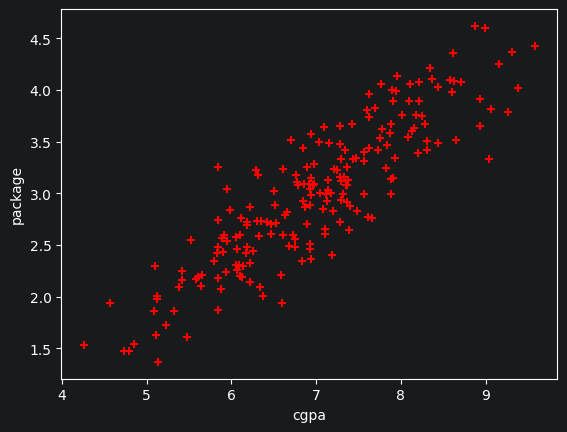

In [50]:
plt.xlabel("cgpa")
plt.ylabel("package")
plt.scatter(df.cgpa, df.package,color="red",marker='+')

In [51]:
corr = df.select_dtypes(include=['number']).corr()
round(corr, 2)

,cgpa,package
cgpa,1.00,0.88
package,0.88,1.00


In [52]:
df["cgpa"].min()

np.float64(4.26)

In [53]:
df["cgpa"].max()

np.float64(9.58)

In [54]:
df["package"].min()

np.float64(1.37)

In [55]:
df["package"].max()

np.float64(4.62)

In [56]:
X = df[["cgpa"]]
Y = df[[ "package"]]


In [57]:
X_train , X_test, Y_train, Y_test = train_test_split(X,Y, test_size = 0.2, random_state = 42)

In [58]:
model = LinearRegression()
model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.57]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-1.03]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [59]:
coefficient = model.coef_
intercept = model.intercept_
print(coefficient)
print(intercept)

[[0.57425647]]
[-1.02700694]


In [60]:
print(f"package= {model.coef_[0][0]:.2f}*cgpa + {model.intercept_[0]:.2f}")

package= 0.57*cgpa + -1.03


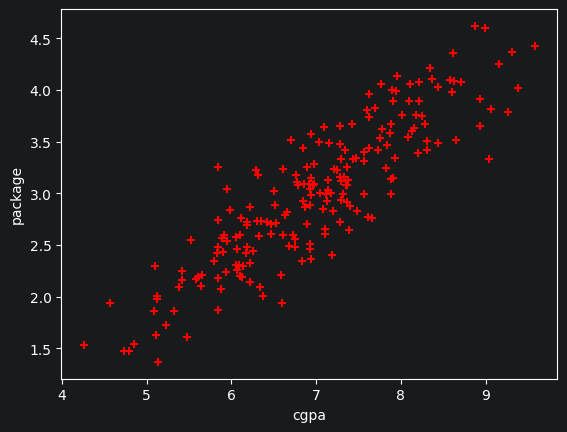

In [61]:
plt.xlabel("cgpa")
plt.ylabel("package")
plt.scatter(df.cgpa, df.package,color="red",marker='+')

In [62]:
y_pred = model.predict(X)

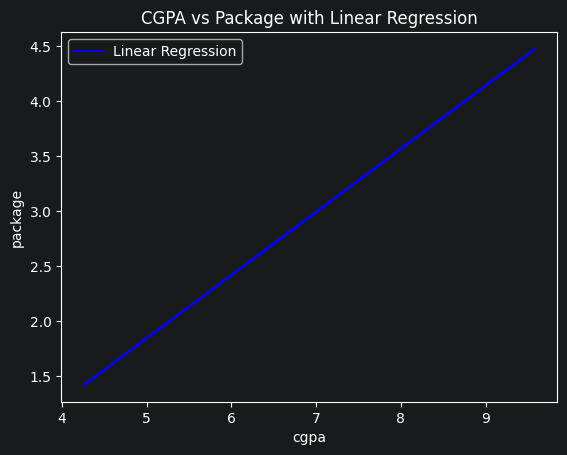

In [63]:
plt.plot(X,y_pred,color="blue", label="Linear Regression")
plt.xlabel("cgpa")
plt.ylabel("package")
plt.title("CGPA vs Package with Linear Regression")
plt.legend()
plt.show()

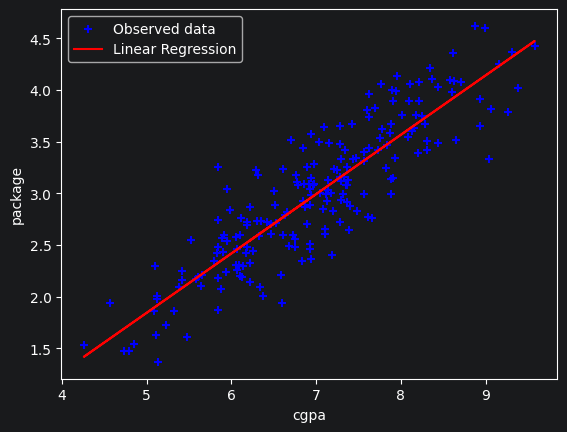

In [64]:
plt.scatter(X,Y , color = "blue", label = "Observed data", marker = "+")
plt.plot(X,y_pred, color = "red", label = "Linear Regression")
plt.xlabel("cgpa")
plt.ylabel("package")
plt.legend()
plt.show()

In [65]:
new_df = df.drop('package', axis = 1)
new_df["predicted package"] = model.predict(new_df)
print(new_df)

     cgpa  predicted package
0    6.89           2.929620
1    5.12           1.913186
2    7.82           3.463679
3    7.42           3.233976
4    6.94           2.958333
..    ...                ...
195  6.93           2.952590
196  5.89           2.355364
197  7.21           3.113382
198  7.63           3.354570
199  6.22           2.544868

[200 rows x 2 columns]


In [66]:
highest = new_df.loc[new_df["predicted package"].idxmax()]
print(highest)

cgpa                 9.58000
predicted package    4.47437
Name: 50, dtype: float64


In [67]:
new_df2 = pd.DataFrame({"cgpa":[5.5,6.5,7.5,8.5,9.5]})
new_df2["predicted package"] = model.predict(new_df2)
print(new_df2)

   cgpa  predicted package
0   5.5           2.131404
1   6.5           2.705660
2   7.5           3.279917
3   8.5           3.854173
4   9.5           4.428430


In [68]:
highest = new_df2.loc[new_df2["predicted package"].idxmax()]
print(highest)

cgpa                 9.50000
predicted package    4.42843
Name: 4, dtype: float64


In [69]:
y_pred = model.predict(X_test)
y_actual = Y_test.values

In [70]:
mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)
rmse = mse**0.5
print(mae)
print(mse)
print(r2)
print(rmse)

0.23150985393278373
0.08417638361329657
0.7730984312051673
0.2901316659954521


In [71]:
actual = Y_test.values.ravel()
predicted = y_pred.ravel()

In [72]:
residuals = actual - predicted

In [73]:
result_df = pd.DataFrame({"actual_package":actual, "predicted package":predicted, "residual":residuals})
print(result_df)

    actual_package  predicted package  residual
0             2.79           2.780313  0.009687
1             3.23           3.136352  0.093648
2             3.26           3.199521  0.060479
3             3.04           2.389819  0.650181
4             3.34           3.526847 -0.186847
5             4.21           3.768035  0.441965
6             2.94           3.165065 -0.225065
7             2.87           2.544868  0.325132
8             2.99           3.176550 -0.186550
9             3.58           3.492392  0.087608
10            1.63           1.907444 -0.277444
11            2.08           2.349621 -0.269621
12            4.08           3.687639  0.392361
13            2.21           2.757343 -0.547343
14            3.47           3.475164 -0.005164
15            3.64           3.044471  0.595529
16            2.74           2.326651  0.413349
17            3.08           3.205263 -0.125263
18            2.17           2.177344 -0.007344
19            2.99           3.314372 -0

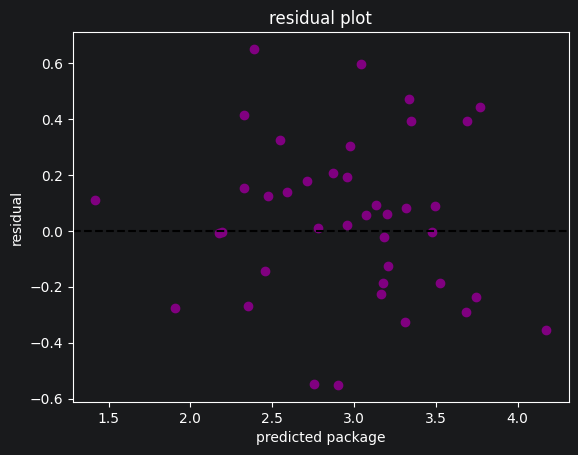

In [74]:
plt.scatter(result_df["predicted package"], result_df["residual"], color = "purple")
plt.axhline(y=0,color="black",linestyle="--")
plt.xlabel("predicted package")
plt.ylabel("residual")
plt.title("residual plot")
plt.show()

In [75]:
df["cgpa_group"] = np.where(df["cgpa"]<7,"Below 7" , "7 or above")
group_avg = df.groupby("cgpa_group")["package"].mean()
print(group_avg)

cgpa_group
7 or above    3.496429
Below 7       2.515294
Name: package, dtype: float64


In [76]:
comparison_df = df[["cgpa","package","cgpa_group"]].copy()
comparison_df["predicted_package"] = model.predict(comparison_df[["cgpa"]]).ravel()
group_pred_avg = comparison_df.groupby("cgpa_group")["predicted_package"].mean()



In [77]:
comparison = pd.DataFrame({"average_actual_package":group_avg, "average_predicted_package":group_pred_avg})
print(comparison)

            average_actual_package  average_predicted_package
cgpa_group                                                   
7 or above                3.496429                   3.490634
Below 7                   2.515294                   2.503770
